
# Supplementary 02 — Ablation and routing analysis

The 13-arm ablation on ROUTER_DEVELOPMENT, the matched paired contrasts with
bootstrap CIs, and the routing/safety state machine on VAL808.

Companion to **§12–§13** of the master notebook.


In [1]:

import sys
from pathlib import Path
sys.path.insert(0, r"D:\Softfors\jup\full_doc_report\Scripts")
import remedfilm_guard as GUARD
GUARD.install()

REPO = Path(r"D:\Softfors\jup")
REPORT = REPO / "full_doc_report"
TABLES = REPORT / "tables"
FIGURES = REPORT / "figures"

import pandas as pd
import numpy as np
import json
from IPython.display import Image, display

for name, verdict in GUARD.self_test():
    assert verdict.startswith("blocked"), f"GUARD FAILED: {name} {verdict}"
print("analysis-only guard verified")


analysis-only guard verified


In [2]:

abl = pd.read_csv(TABLES / "REMEDFILM_ABLATION_RESULTS.csv")
print("population:", abl.population.iloc[0])
print("arms      :", len(abl))
abl[["arm", "n_routed", "mean_true_delta_dice_routed",
     "harmful_activation_share", "benefit_capture_vs_positive_mass"]].to_string(index=False)


population: ROUTER_DEVELOPMENT_4957
arms      : 13


'arm  n_routed  mean_true_delta_dice_routed  harmful_activation_share  benefit_capture_vs_positive_mass\n A0         0                     0.000000                  0.000000                          0.000000\n A1      4957                     0.001658                  0.426669                          1.000000\n A2      1239                     0.001413                  0.443906                          0.245520\n A3      1239                     0.007185                  0.318805                          0.584331\n A4      1239                     0.007119                  0.319613                          0.582158\n A5      1239                    -0.000433                  0.464084                          0.184251\n A6      1239                     0.007247                  0.332526                          0.602199\n A7      1239                     0.007247                  0.332526                          0.602199\n A8      1205                     0.007516                  0.3

In [3]:

# Rank arms by routed mean improvement and show the harm cost of each.
ranked = abl.sort_values("mean_true_delta_dice_routed", ascending=False)
ranked[["arm", "mean_true_delta_dice_routed", "harmful_activation_share",
        "n_beneficial_routed", "n_harmful_routed"]].to_string(index=False)


'arm  mean_true_delta_dice_routed  harmful_activation_share  n_beneficial_routed  n_harmful_routed\n A8                     0.007516                  0.323651                  815               390\n A6                     0.007247                  0.332526                  827               412\n A7                     0.007247                  0.332526                  827               412\n A3                     0.007185                  0.318805                  844               395\n A4                     0.007119                  0.319613                  843               396\n R1                     0.003320                  0.373688                  723               463\n A1                     0.001658                  0.426669                 2775              2115\n A2                     0.001413                  0.443906                  669               550\n R3                     0.001251                  0.422922                  702               524\n R2      

In [4]:

bs = pd.read_csv(REPO / "reports/tables/phase28_table_08_bootstrap_statistics.csv")
bs["excludes_zero"] = (bs.ci95_low > 0) | (bs.ci95_high < 0)
bs[["contrast", "n", "mean_difference", "ci95_low", "ci95_high", "excludes_zero"]].to_string(index=False)
print()
a8 = bs[bs.contrast == "A8_vs_A7"].iloc[0]
print("PRESERVED FINDING — A8 vs A7 95% CI includes zero:")
print(f"  point {a8.mean_difference:+.3e}  CI [{a8.ci95_low:+.3e}, {a8.ci95_high:+.3e}]")



PRESERVED FINDING — A8 vs A7 95% CI includes zero:
  point +1.572e-05  CI [-1.431e-05, +5.101e-05]


In [5]:

ps = pd.read_csv(TABLES / "REMEDFILM_INTERNAL_PER_SAMPLE.csv")
tab = ps.groupby("branch").agg(
    n=("sample_id", "size"),
    mean_delta=("delta_dice", "mean"),
    min_delta=("delta_dice", "min"),
    max_delta=("delta_dice", "max"),
).reset_index()
tab["share_of_808"] = (tab.n / len(ps)).round(4)
tab


,branch,n,mean_delta,min_delta,max_delta,share_of_808
0,EXECUTE_THEN_ACCEPT,266,0.009204,-0.067387,0.125767,0.3292
1,EXECUTE_THEN_REJECT,13,0.000000,0.000000,0.000000,0.0161
2,SKIP_GLOBAL,529,0.000000,0.000000,0.000000,0.6547


In [6]:

# Population separation is a hard rule, not a convention.
print("ROUTER_DEVELOPMENT (ablation) : 4,957 images, 1,239 routed")
print("VAL808 (routing analysis)     : 808 images, 279 routed")
print("EXTERNAL884                   : separate cohorts, never pooled")
print()
print("No statistic in this notebook mixes them.")


ROUTER_DEVELOPMENT (ablation) : 4,957 images, 1,239 routed
VAL808 (routing analysis)     : 808 images, 279 routed
EXTERNAL884                   : separate cohorts, never pooled

No statistic in this notebook mixes them.


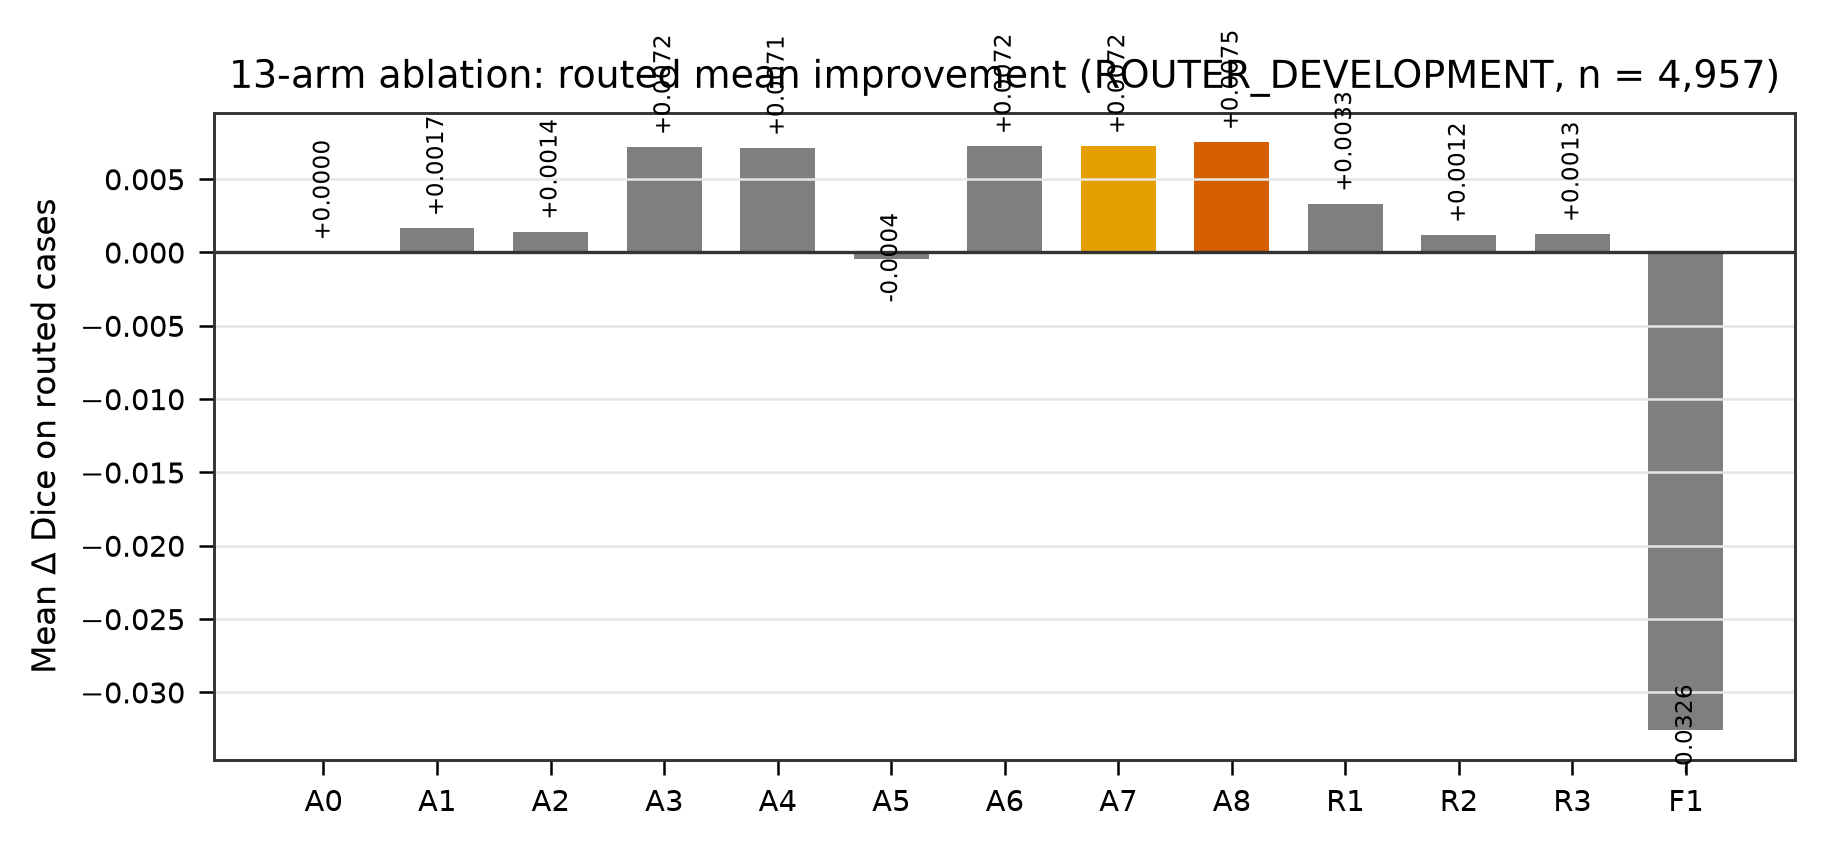

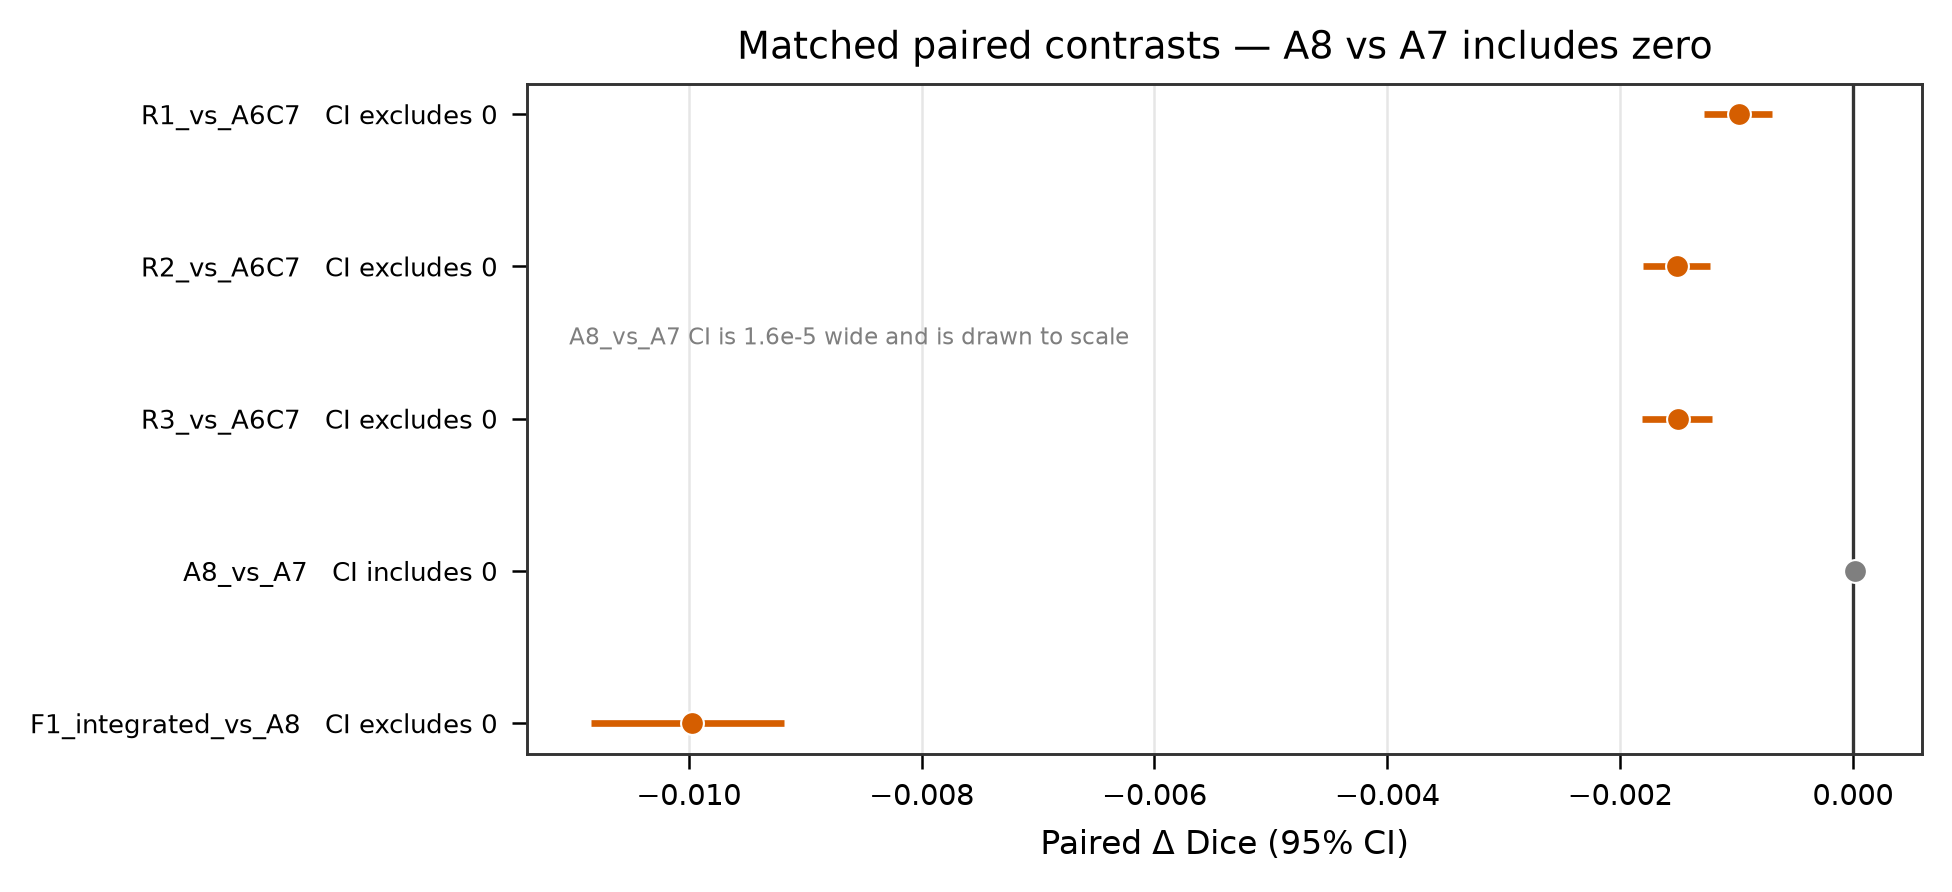

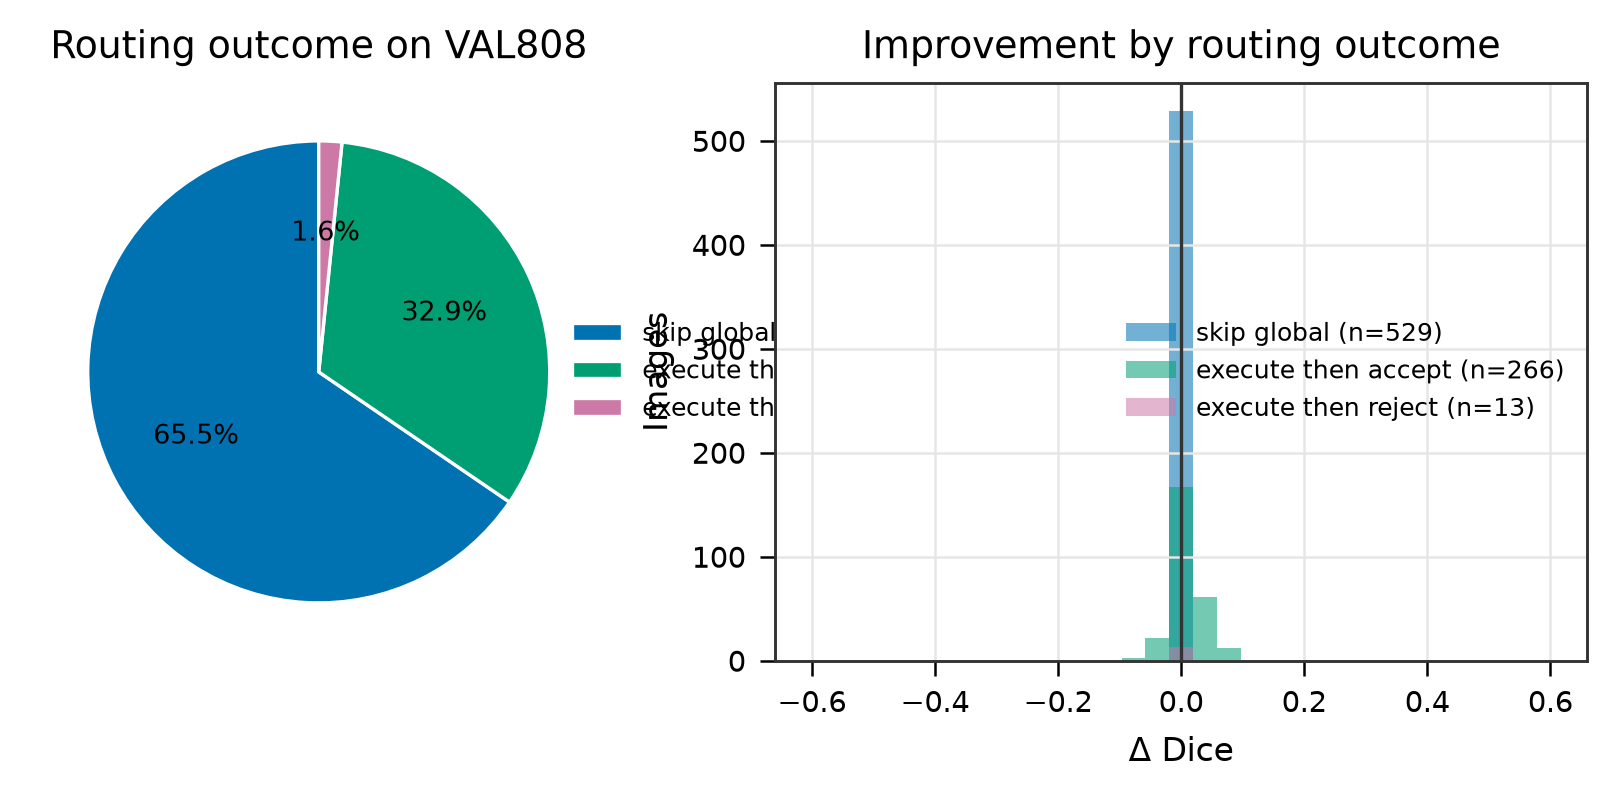

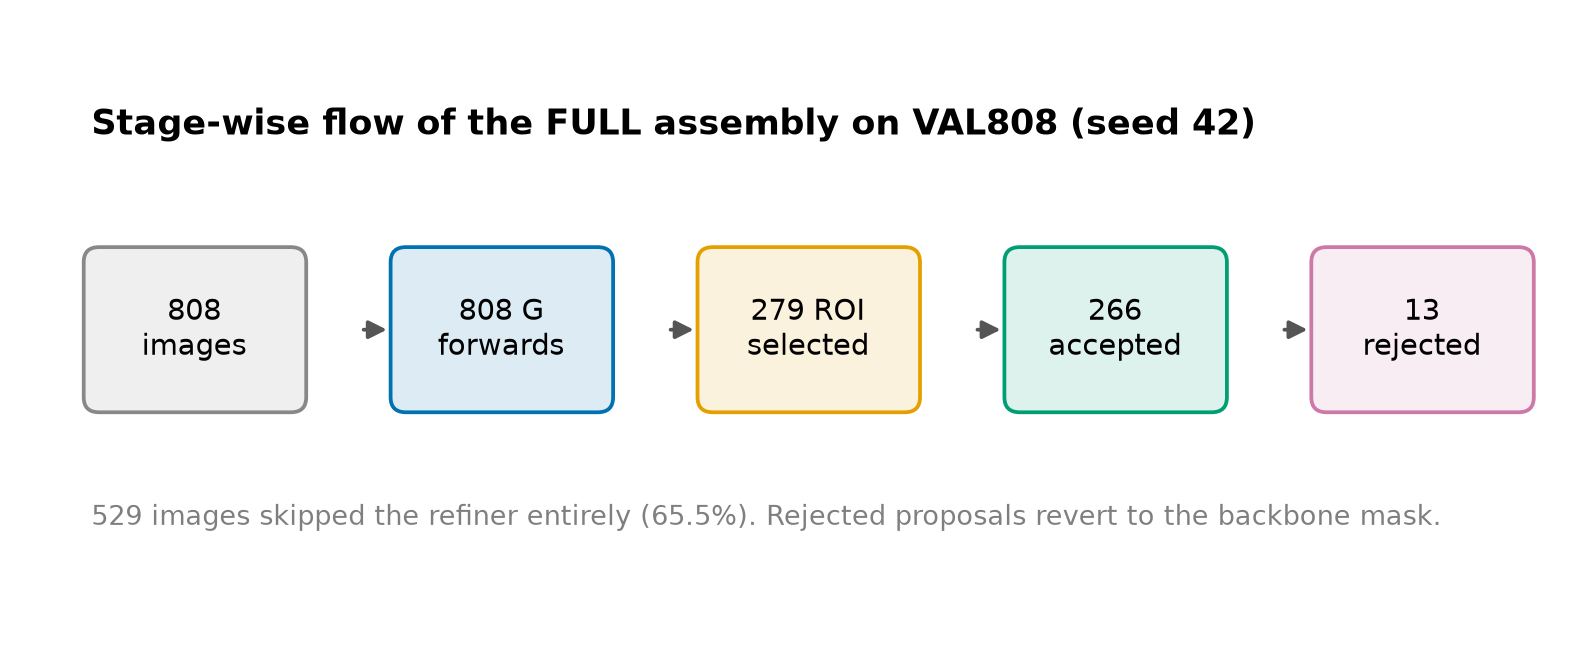

In [7]:

for f in ["ablation/ABL01_arm_mean_delta", "ablation/ABL02_paired_contrasts_forest",
          "routing_safety/RT01_routing_outcomes", "routing_safety/RT02_stage_flow"]:
    display(Image(filename=str(FIGURES / f"{f}.png"), width=720))


In [8]:

# Negative control: enforcement must be real.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test())
print("OK")


  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
OK
